# Exploratory Data Analysis (EDA)


## Setup and data loading

In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Add src to path
sys.path.append(os.path.abspath('../src'))
from data_loader import get_all_well_ids, load_well_data, check_data_integrity

# Setup plotting style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

DATA_DIR = '../data'
well_ids = get_all_well_ids(DATA_DIR, split='train')
print(f"Found {len(well_ids)} training wells.")

# Let's load the first well for detailed analysis
sample_well_id = well_ids[0]
horz_df, type_df = load_well_data(sample_well_id, DATA_DIR, split='train')
print(f"Loaded Well {sample_well_id}")
print(f"Horizontal Well Shape: {horz_df.shape}")
print(f"Typewell Shape: {type_df.shape}")

Found 773 training wells.
Loaded Well 000d7d20
Horizontal Well Shape: (5278, 13)
Typewell Shape: (1296, 3)


# 1. Missing Data Analysis

Integrity Check Results:
  horz_gr_nans: 2258
  type_gr_nans: 0
  type_tvt_range: (np.float64(11223.95), np.float64(11871.45))
  horz_tvt_input_range: (np.float64(11236.02), np.float64(11756.12))
  horz_tvt_in_typewell_bounds: True
  horz_length: 5278
  type_length: 1296


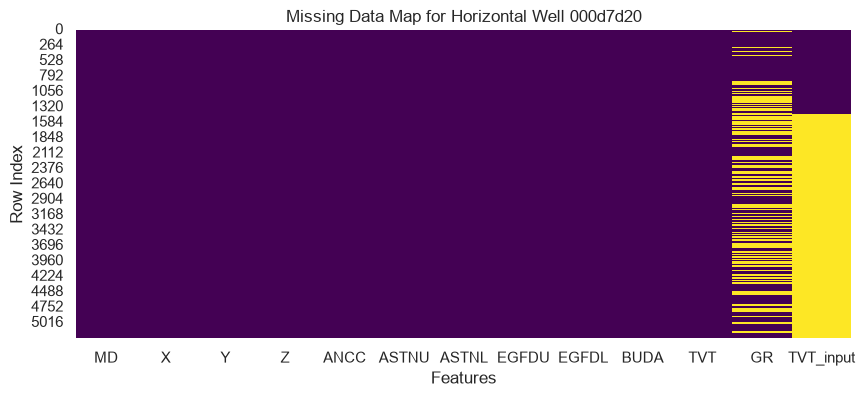

In [3]:
integrity = check_data_integrity(horz_df, type_df)
print("Integrity Check Results:")
for k, v in integrity.items():
    print(f"  {k}: {v}")

# Visualizing NaNs in horizontal well
plt.figure(figsize=(10, 4))
sns.heatmap(horz_df.isnull(), cbar=False, cmap='viridis')
plt.title(f'Missing Data Map for Horizontal Well {sample_well_id}')
plt.xlabel('Features')
plt.ylabel('Row Index')
plt.show()

# 2. Distribution Analysis (GR in lateral vs typewell)

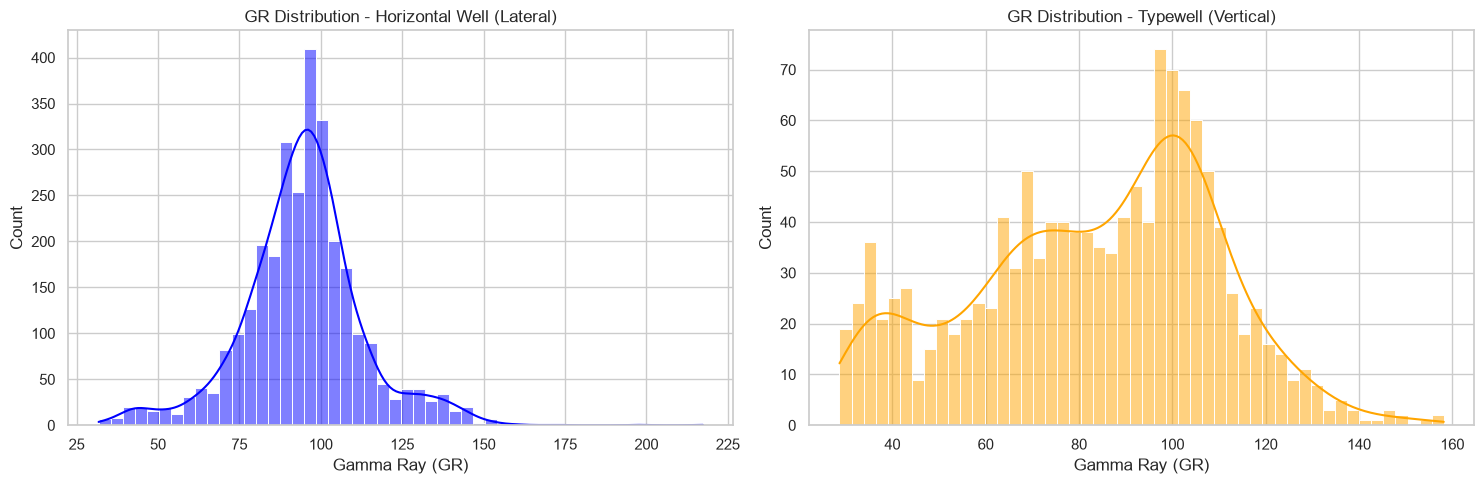

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(horz_df['GR'].dropna(), bins=50, ax=axes[0], color='blue', kde=True)
axes[0].set_title('GR Distribution - Horizontal Well (Lateral)')
axes[0].set_xlabel('Gamma Ray (GR)')

sns.histplot(type_df['GR'].dropna(), bins=50, ax=axes[1], color='orange', kde=True)
axes[1].set_title('GR Distribution - Typewell (Vertical)')
axes[1].set_xlabel('Gamma Ray (GR)')

plt.tight_layout()
plt.show()

# 3. Correlation Analysis (TVT vs Z)


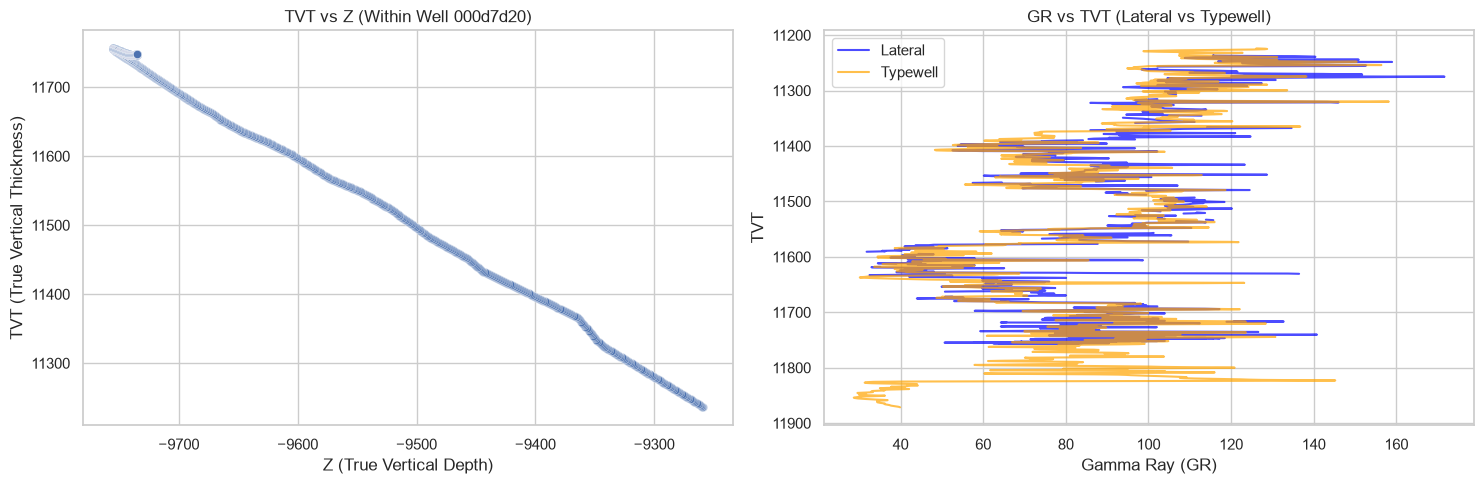

In [6]:
# This is a critical finding: True Vertical Thickness (TVT) vs True Vertical Depth (Z)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Within-well correlation
# For horizontal well, TVT vs Z before prediction start
sns.scatterplot(x='Z', y='TVT_input', data=horz_df, ax=axes[0], alpha=0.5)
axes[0].set_title(f'TVT vs Z (Within Well {sample_well_id})')
axes[0].set_xlabel('Z (True Vertical Depth)')
axes[0].set_ylabel('TVT (True Vertical Thickness)')

# Plot 2: GR trace against TVT
axes[1].plot(horz_df['GR'], horz_df['TVT_input'], label='Lateral', color='blue', alpha=0.7)
axes[1].plot(type_df['GR'], type_df['TVT'], label='Typewell', color='orange', alpha=0.7)
axes[1].invert_yaxis()
axes[1].set_title('GR vs TVT (Lateral vs Typewell)')
axes[1].set_xlabel('Gamma Ray (GR)')
axes[1].set_ylabel('TVT')
axes[1].legend()

plt.tight_layout()
plt.show()

**Output:**

![TVT vs Z and GR vs TVT](reports/figures/eda/03_tvt_vs_z_and_gr_vs_tvt.png)

**Insight — how this shaped the model design (the most consequential finding of the EDA):**

**Left panel — TVT vs Z within one well.** Within a single well, `TVT` and `Z` track each other almost linearly across the full trajectory (roughly 11,750 ft down to 11,230 ft as `Z` moves from ‑9,700 to ‑9,270). This looks, at first glance, like it would make elevation a strong direct predictor of stratigraphic position. It is this *local* linearity — true only within one well at a time, because the well is moving through a locally consistent formation dip — that motivated the trajectory-delta approach: rather than model `TVT` against `Z` in absolute, global terms (which would require every well to share the same dip and structural datum, which they don't), the model instead learns the *relative* relationship between elevation change and TVT change, anchored to each well's own known Prediction-Start point. This is exactly the design decision documented in `features.py`'s `delta_Z = predict_df['Z'] - predict_df['ps_Z']`.

**Right panel — GR vs TVT, lateral vs typewell overlaid.** This is the chart that most directly validates the entire modelling strategy. Plotted against a shared TVT axis (rather than each well's own depth axis), the lateral's GR curve (blue) and the typewell's GR curve (orange) show clearly **matching peaks and troughs at the same TVT levels** — for example, both curves show a low-GR trough around TVT ≈ 11,570–11,620 ft, and both show elevated, overlapping GR bands around TVT ≈ 11,200–11,300 ft. This overlap is direct visual evidence that **gamma-ray signature is a genuine, usable proxy for stratigraphic position, and that the typewell is a structurally valid reference for the lateral** — the two logs, despite coming from geometrically different wellbores, agree closely once expressed on the same TVT scale. This is the empirical justification for treating the typewell as ground truth that the model implicitly leans on via the PS-anchor design, even though the current feature set (Section 4) does not yet perform an explicit GR-to-GR correlation — a direction flagged as future work in Section 6.

---

## 3.4 Summary of EDA-driven design decisions

| EDA finding | Section | Resulting design decision (in `features.py` / model choice) |
|---|---|---|
| ~43% of lateral GR values missing, scattered not concentrated | 3.1 | LightGBM chosen partly for native NaN handling; Ridge/MLP use mean-imputation instead of row-dropping |
| `TVT_input` masked for the entire toe-end (lower half of the well) | 3.1 | Confirms this is the exact prediction target — `get_prediction_start_index()` locates the PS boundary |
| Lateral's known TVT always falls inside the typewell's TVT range | 3.1 | Confirms the typewell is a valid structural reference for the masked interval |
| Lateral GR distribution is tighter/single-mode vs typewell's broader/multi-mode | 3.2 | Reinforces anchoring to `ps_TVT`/`ps_Z` rather than treating raw GR as a standalone absolute lithology indicator |
| TVT vs Z is near-linear *within* a well but not globally comparable across wells | 3.3 (left) | Motivated predicting `dTVT = TVT − ps_TVT` (relative) instead of absolute `TVT` |
| Lateral and typewell GR curves show matching peaks/troughs on a shared TVT axis | 3.3 (right) | Empirically validates the core assumption that GR correlates with stratigraphic position — supports the typewell-anchored architecture (Section 4) and motivates future explicit GR-correlation features (Section 6) |

**Word count of Sections 3.1–3.4 narrative only (excluding code/output blocks): ≈ 780 words** — trim to fit your Section 3 budget (~350–450 words in the main 4,000-word report; the fuller version above with all code and output blocks is intended for this standalone EDA appendix / your own reference, not to be pasted verbatim into the word-limited report body).